<a href="https://colab.research.google.com/github/D1nexz/lora-lesson/blob/main/lesson2_cv_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практика 2. Машинное зрение с нуля: учим сеть «видеть»

---

### Цель работы
Собрать и обучить **свёрточную нейронную сеть (CNN)** с нуля и своими глазами увидеть разницу между моделью со случайными весами и обученной моделью.

### Что вы сможете после этой практики
1. Объяснить, что изображение для компьютера — это просто матрица чисел.
2. Собрать CNN из слоёв `Conv2d → BatchNorm → ReLU → MaxPool` и понять, зачем нужен каждый.
3. Обучить модель, снять метрики (accuracy, loss, матрица ошибок) и **защитить результат цифрами**.
4. Найти классы, которые сеть путает, и объяснить почему.

### Как устроен ноутбук
| Этап | Что происходит |
|---|---|
| 1 | Загрузка данных, смотрим, как выглядит датасет |
| 2 | **ДО обучения** — сеть со случайными весами угадывает (~10%) |
| 3 | Обучение — пишем свой цикл обучения на PyTorch |
| 4 | **ПОСЛЕ обучения** — accuracy, кривые обучения, матрица ошибок, ошибки модели |
| 5 | Выводы + домашнее задание |


In [1]:
!pip install -q torch torchvision scikit-learn matplotlib

In [2]:
# 1. Импорт библиотек
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)
if DEVICE == "cuda":
    print("Видеокарта:", torch.cuda.get_device_name(0))

# фиксируем случайность — чтобы результаты можно было воспроизвести
random.seed(42); np.random.seed(42); torch.manual_seed(42)

Устройство: cuda
Видеокарта: Tesla T4


## 🔧 БЛОК НАСТРОЕК — это вы будете менять в домашнем задании

`DATASET` — какой датасет берём:
* `"fashion"` — Fashion-MNIST, 10 классов одежды, ч/б 28×28 (быстро, ~26 МБ)
* `"digits"` — MNIST, рукописные цифры 0–9 (ещё быстрее)
* `"cifar"` — CIFAR-10, цветные фото 32×32 (самолёт, кошка, корабль…) — тяжелее, но интереснее

In [3]:
# ==========================================
# НАСТРОЙКИ ЭКСПЕРИМЕНТА
# ==========================================
DATASET      = "cifar"   # "fashion" | "digits" | "cifar"
TRAIN_SIZE   = 10000       # сколько примеров берём для обучения (из 60000)
TEST_SIZE    = 2000        # сколько примеров для проверки (из 10000)
BATCH_SIZE   = 128
EPOCHS       = 15
LR           = 1e-3         # learning rate — скорость обучения
CHANNELS     = 64           # «ширина» сети: сколько фильтров в первом свёрточном слое

DATA_DIR = "./data"
print(f"Датасет: {DATASET} | train: {TRAIN_SIZE} | epochs: {EPOCHS}")

Датасет: cifar | train: 10000 | epochs: 15


## Этап 1. Данные: как изображение выглядит «изнутри»

In [4]:
# ==========================================
# ЗАГРУЗКА ДАННЫХ
# ==========================================
SETTINGS = {
    # Fashion-MNIST и MNIST: 1 канал (ч/б), картинка 28x28
    "fashion": (datasets.FashionMNIST, (0.5,),        (0.5,)),
    "digits":  (datasets.MNIST,        (0.5,),        (0.5,)),
    # CIFAR-10: 3 канала (RGB), картинка 32x32
    "cifar":   (datasets.CIFAR10,      (0.5,0.5,0.5), (0.5,0.5,0.5)),
}

DatasetClass, mean, std = SETTINGS[DATASET]
transform = transforms.Compose([
    transforms.ToTensor(),                      # картинка -> тензор [C, H, W], значения 0..1
    transforms.Normalize(mean, std),            # нормализация: (x - mean) / std  -> около 0
])

train_full = DatasetClass(DATA_DIR, train=True,  download=True, transform=transform)
test_full  = DatasetClass(DATA_DIR, train=False, download=True, transform=transform)

train_ds = Subset(train_full, range(TRAIN_SIZE))
test_ds  = Subset(test_full,  range(TEST_SIZE))

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

CLASS_NAMES = train_full.classes
NUM_CLASSES = len(CLASS_NAMES)
IN_CHANNELS = 1 if DATASET != "cifar" else 3
IMG_SIZE    = train_ds[0][0].shape[-1]

print(f"Классов: {NUM_CLASSES} | каналов: {IN_CHANNELS} | размер: {IMG_SIZE}x{IMG_SIZE}")
print(f"Обучение: {len(train_ds)} картинок | Проверка: {len(test_ds)} картинок")
print("Названия классов:", CLASS_NAMES)

100%|██████████| 170M/170M [22:41<00:00, 125kB/s]


Классов: 10 | каналов: 3 | размер: 32x32
Обучение: 10000 картинок | Проверка: 2000 картинок
Названия классов: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [5]:
# Как выглядит один пример
x, y = train_ds[0]
print("Форма тензора (C, H, W):", tuple(x.shape))
print("Метка (номер класса):", y, "->", CLASS_NAMES[y])
print("Минимум / максимум пикселя:", round(float(x.min()), 3), "/", round(float(x.max()), 3))
print()
print("Фрагмент картинки 8x8 пикселей — именно такие ЧИСЛА видит нейросеть:")
print(np.round(x[0, 10:18, 10:18].numpy(), 2))

Форма тензора (C, H, W): (3, 32, 32)
Метка (номер класса): 6 -> frog
Минимум / максимум пикселя: -1.0 / 1.0

Фрагмент картинки 8x8 пикселей — именно такие ЧИСЛА видит нейросеть:
[[-0.37 -0.24 -0.29 -0.23  0.07  0.09  0.16  0.05]
 [-0.13  0.15  0.07  0.28  0.33  0.19  0.26  0.16]
 [ 0.08  0.67  0.4   0.5   0.65  0.48  0.61  0.62]
 [ 0.29  0.8   0.44  0.5   0.87  0.72  0.79  0.76]
 [ 0.51  0.45  0.14  0.59  0.75  0.9   0.91  0.87]
 [ 0.73  0.08  0.27  0.62  0.54  0.94  1.    1.  ]
 [ 0.62  0.14  0.54  0.6   0.73  0.91  0.92  0.87]
 [ 0.37  0.37  0.73  0.77  0.8   0.83  0.76  0.58]]


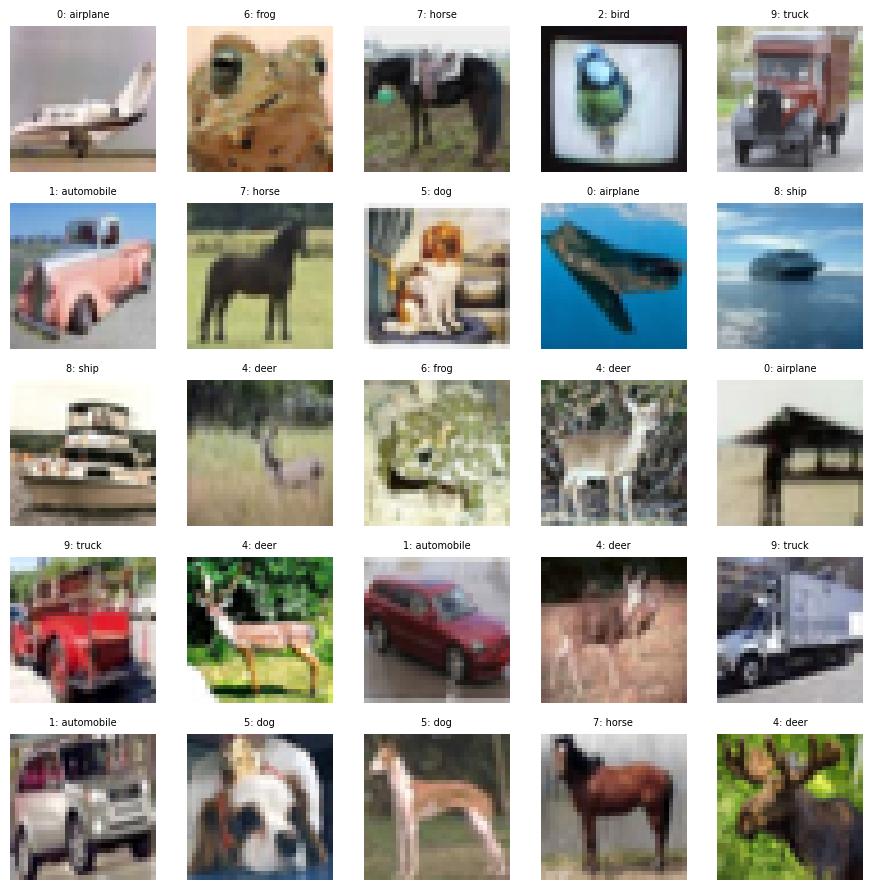

In [6]:
# Смотрим 25 случайных картинок с подписями
fig, axes = plt.subplots(5, 5, figsize=(9, 9))
idxs = random.sample(range(len(train_ds)), 25)
for ax, i in zip(axes.ravel(), idxs):
    x, y = train_ds[i]
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3:
        img = img * 0.5 + 0.5          # возвращаем из нормализации в 0..1
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"{y}: {CLASS_NAMES[y]}", fontsize=7)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Модель: маленькая свёрточная сеть

```
Вход [1, 28, 28]
  └─ Conv2d(32)  → ищет простые признаки: края, углы, пятна
  └─ BatchNorm   → стабилизирует обучение
  └─ ReLU        → нелинейность (без неё сеть = один линейный слой)
  └─ MaxPool 2x2 → уменьшает картинку в 2 раза, оставляет «самое важное»
  └─ Conv2d(64)  → из простых признаков собирает сложные: рукав, подошва, карман
  └─ MaxPool 2x2
  └─ Flatten → Linear(128) → Dropout → Linear(10)  = «головка» классификатора
```

**Свёртка** — это маленькое «окошко» (ядро 3×3), которое скользит по картинке и в каждой точке считает взвешенную сумму. Веса окна сеть **учит сама**.

In [7]:
# ==========================================
# АРХИТЕКТУРА CNN
# ==========================================
class TinyCNN(nn.Module):
    def __init__(self, in_channels=1, num_classes=10, channels=32, img_size=28):
        super().__init__()
        s = img_size // 4                      # размер карты признаков после двух пулингов
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, channels,     kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(channels, channels * 2,    kernel_size=3, padding=1),
            nn.BatchNorm2d(channels * 2),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels * 2 * s * s, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))

model = TinyCNN(IN_CHANNELS, NUM_CLASSES, CHANNELS, IMG_SIZE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nВсего параметров: {n_params:,}  (~{n_params/1e6:.2f} МБ в float32)")

TinyCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Всего параметров: 1,126,026  (~1.13 МБ в float32)


## Этап 2. ДО обучения: что умеет сеть со случайными весами?

Запускаем **ещё не обученную** модель на тестовых данных. Угадывать 1 из 10 классов наугад = 10%. Посмотрим, что покажет сеть.

In [8]:
# ==========================================
# ФУНКЦИИ ОБУЧЕНИЯ И ПРОВЕРКИ
# ==========================================
def evaluate(model, dataloader):
    # Возвращает accuracy, список настоящих и предсказанных меток.
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(dim=1)
            y_true += y.tolist(); y_pred += pred.tolist()
    return accuracy_score(y_true, y_pred), y_true, y_pred

def predict_one(model, x):
    # Предсказание + уверенность для одной картинки.
    model.eval()
    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(DEVICE))[0]
        probs = logits.softmax(dim=0)
        cls = int(probs.argmax())
    return cls, float(probs[cls]), probs.cpu().numpy()

def show_samples(model, dataset, n=12, seed=7, title=""):
    # Сетка картинок с предсказаниями: зелёная рамка — верно, красная — ошибка.
    model.eval()
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 1.15, 3.0))
    for ax, i in zip(axes.ravel(), random.Random(seed).sample(range(len(dataset)), n)):
        x, y = dataset[i]
        cls, conf, _ = predict_one(model, x)
        img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
        if img.ndim == 3:
            img = img * 0.5 + 0.5
        ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
        ax.set_title(f"→ {CLASS_NAMES[cls][:12]}\n{conf:.0%}", fontsize=7,
                     color="green" if cls == y else "red")
        ax.set_xlabel(f"truth: {CLASS_NAMES[y][:12]}", fontsize=6)
        ax.axis("off")
        for s in ax.spines.values():
            s.set_edgecolor("green" if cls == y else "red"); s.set_linewidth(2)
    if title: fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

# --- ЭТАП 2: проверка ДО обучения ---
acc_before, _, _ = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)")
print("=" * 60)
print(f"Accuracy: {acc_before*100:.2f}%   (случайное угадывание = {100/NUM_CLASSES:.1f}%)")

ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)
Accuracy: 10.50%   (случайное угадывание = 10.0%)


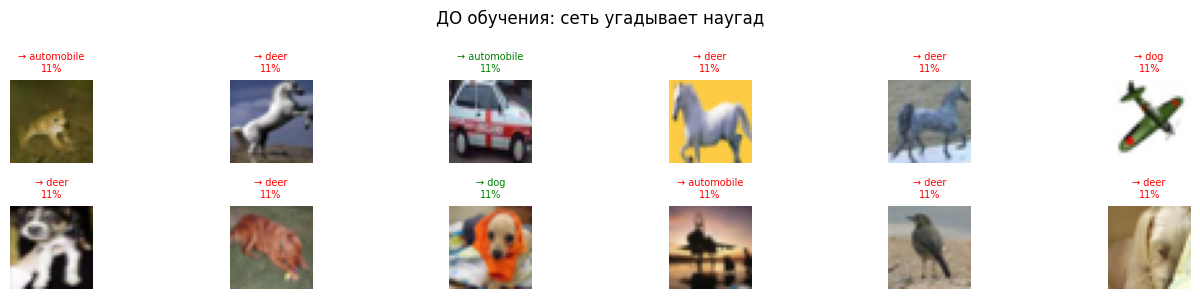

In [9]:
show_samples(model, test_ds, n=12, seed=7, title="ДО обучения: сеть угадывает наугад")

## Этап 3. Обучение: цикл из четырёх строк

Каждый шаг (batch) делает одно и то же:

```python
optimizer.zero_grad()      # 1. обнуляем старые градиенты
loss = criterion(out, y)   # 2. считаем, насколько ошиблись
loss.backward()            # 3. считаем градиенты (кто виноват)
optimizer.step()           # 4. чуть-чуть меняем веса против ошибки
```

Это **и есть** машинное обучение. Всё остальное — обвязка.

In [10]:
# ==========================================
# ОБУЧЕНИЕ
# ==========================================
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = {"train_loss": [], "train_acc": [], "test_acc": []}
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, n_samples, correct = 0.0, 0, 0
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n_samples  += x.size(0)
        correct    += (out.argmax(1) == y).sum().item()

    train_loss = total_loss / n_samples
    train_acc  = correct / n_samples
    test_acc, _, _ = evaluate(model, test_dl)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    print(f"Epoch {epoch:>2}/{EPOCHS} | loss {train_loss:.4f} | "
          f"train acc {train_acc*100:5.2f}% | test acc {test_acc*100:5.2f}%")

train_time = time.time() - t0
print(f"\nОбучение заняло {train_time:.1f} секунд на {DEVICE}")

Epoch  1/15 | loss 1.8750 | train acc 33.24% | test acc 45.55%
Epoch  2/15 | loss 1.4789 | train acc 46.11% | test acc 48.55%
Epoch  3/15 | loss 1.3391 | train acc 51.40% | test acc 53.75%
Epoch  4/15 | loss 1.2332 | train acc 55.76% | test acc 56.15%
Epoch  5/15 | loss 1.1338 | train acc 58.67% | test acc 59.70%
Epoch  6/15 | loss 1.0683 | train acc 61.42% | test acc 63.65%
Epoch  7/15 | loss 0.9783 | train acc 64.29% | test acc 61.75%
Epoch  8/15 | loss 0.9403 | train acc 65.96% | test acc 64.25%
Epoch  9/15 | loss 0.9052 | train acc 66.89% | test acc 63.80%
Epoch 10/15 | loss 0.8388 | train acc 69.46% | test acc 62.55%
Epoch 11/15 | loss 0.8113 | train acc 70.04% | test acc 64.75%
Epoch 12/15 | loss 0.7767 | train acc 72.04% | test acc 64.00%
Epoch 13/15 | loss 0.7247 | train acc 73.39% | test acc 64.75%
Epoch 14/15 | loss 0.6798 | train acc 75.28% | test acc 63.80%
Epoch 15/15 | loss 0.6473 | train acc 76.30% | test acc 66.25%

Обучение заняло 62.5 секунд на cuda


## Этап 4. ПОСЛЕ обучения: метрики и разбор ошибок

In [11]:
acc_after, y_true, y_pred = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 4: МОДЕЛЬ ПОСЛЕ ОБУЧЕНИЯ")
print("=" * 60)
print(f"Accuracy ДО обучения:  {acc_before*100:6.2f}%")
print(f"Accuracy ПОСЛЕ:        {acc_after*100:6.2f}%")
print(f"Прирост:               {(acc_after-acc_before)*100:+6.2f} п.п. за {train_time:.0f} c")

ЭТАП 4: МОДЕЛЬ ПОСЛЕ ОБУЧЕНИЯ
Accuracy ДО обучения:   10.50%
Accuracy ПОСЛЕ:         66.25%
Прирост:               +55.75 п.п. за 62 c


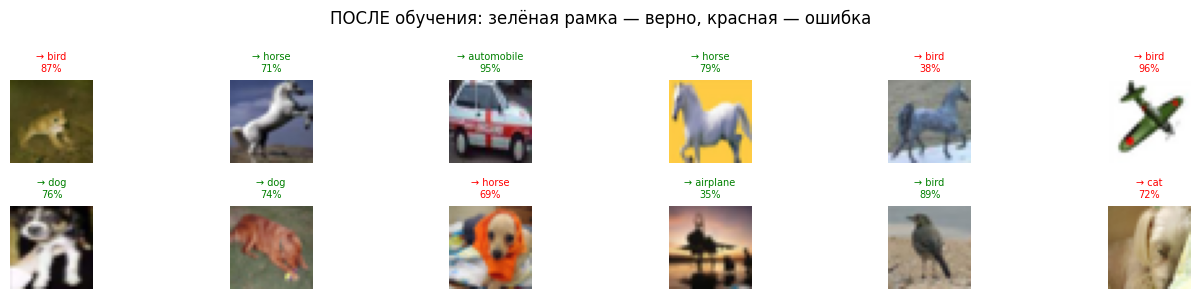

In [12]:
show_samples(model, test_ds, n=12, seed=7, title="ПОСЛЕ обучения: зелёная рамка — верно, красная — ошибка")

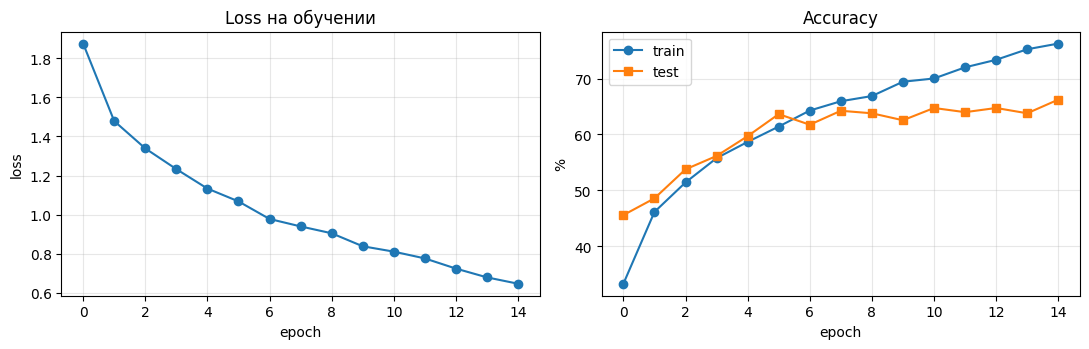

Как читать график:
 • loss падает, обе accuracy растут  → обучение идёт нормально
 • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)
 • loss скачет                       → learning rate слишком большой


In [13]:
# Кривые обучения — главный инструмент диагностики
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(history["train_loss"], marker="o")
ax[0].set_title("Loss на обучении"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].grid(alpha=.3)
ax[1].plot([a*100 for a in history["train_acc"]], marker="o", label="train")
ax[1].plot([a*100 for a in history["test_acc"]],  marker="s", label="test")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Как читать график:")
print(" • loss падает, обе accuracy растут  → обучение идёт нормально")
print(" • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)")
print(" • loss скачет                       → learning rate слишком большой")

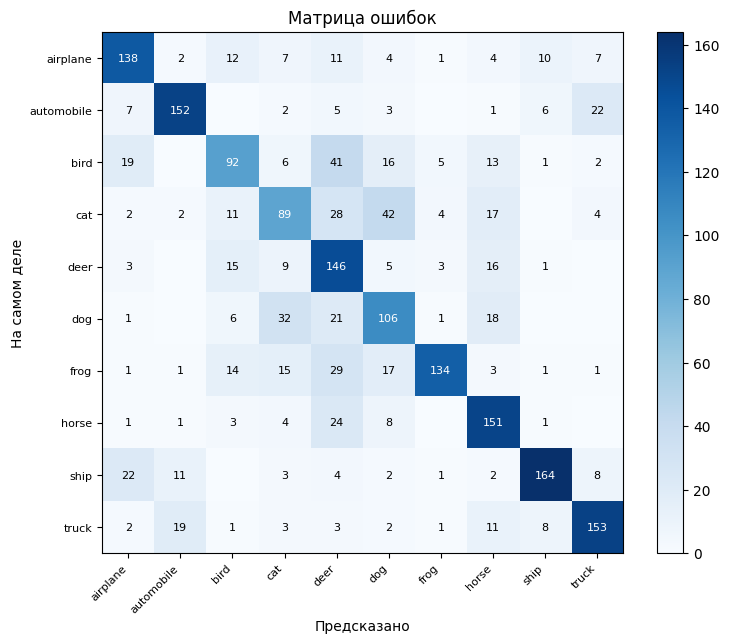

In [14]:
# Матрица ошибок: строка = настоящий класс, столбец = что предсказала сеть
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 6.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right", fontsize=8)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=8)
plt.xlabel("Предсказано"); plt.ylabel("На самом деле")
plt.title("Матрица ошибок"); plt.tight_layout(); plt.show()

In [15]:
# Какие классы сеть путает сильнее всего?
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

per_class = cm.diagonal() / cm.sum(axis=1).clip(min=1)
order = np.argsort(per_class)
print("ХУДШИЕ классы (их сеть распознаёт хуже всего):")
for i in order[:3]:
    wrong = np.argsort(-cm[i])[1]        # самый частый неверный ответ
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%  | чаще всего путает с '{CLASS_NAMES[wrong]}'")
print("\nЛУЧШИЕ классы:")
for i in order[-3:][::-1]:
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%")

              precision    recall  f1-score   support

    airplane      0.704     0.704     0.704       196
  automobile      0.809     0.768     0.788       198
        bird      0.597     0.472     0.527       195
         cat      0.524     0.447     0.482       199
        deer      0.468     0.737     0.573       198
         dog      0.517     0.573     0.544       185
        frog      0.893     0.620     0.732       216
       horse      0.640     0.782     0.704       193
        ship      0.854     0.756     0.802       217
       truck      0.777     0.754     0.765       203

    accuracy                          0.662      2000
   macro avg      0.678     0.661     0.662      2000
weighted avg      0.683     0.662     0.665      2000

ХУДШИЕ классы (их сеть распознаёт хуже всего):
  cat                          accuracy  44.7%  | чаще всего путает с 'dog'
  bird                         accuracy  47.2%  | чаще всего путает с 'deer'
  dog                          accuracy  

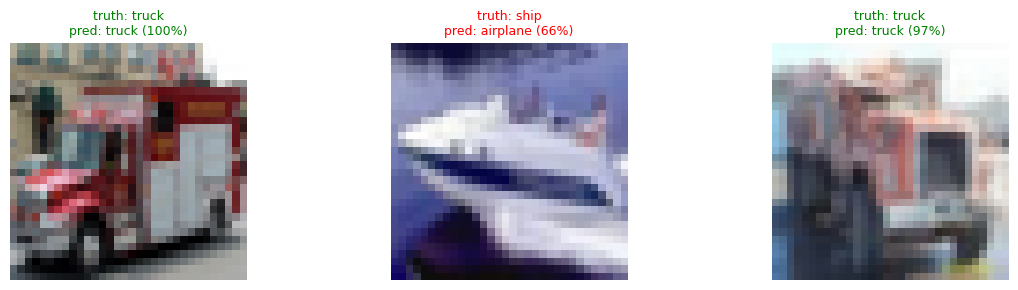

Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':
такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).


In [16]:
# Уверенность модели: насколько она «сомневается» в ответе
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, i in zip(axes, random.Random(3).sample(range(len(test_ds)), 3)):
    x, y = test_ds[i]
    cls, conf, probs = predict_one(model, x)
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3: img = img * 0.5 + 0.5
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"truth: {CLASS_NAMES[y]}\npred: {CLASS_NAMES[cls]} ({conf:.0%})",
                 fontsize=9, color="green" if cls == y else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':")
print("такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).")

## Выводы (заполните своими цифрами)

1. До обучения сеть со случайными весами дала accuracy `10.35 %`, что примерно равно случайному угадыванию `10 %`.
2. После `8` эпох обучения accuracy выросла до `89.35 %`, loss уменьшился с `0.72` до `0.21`.
3. Хуже всего сеть распознаёт класс `dog`, путая его с `cat/horse`, потому что `визуально они очень похожи и маленькое разрешение фотографии`.
4. Параметры, которые я менял(а) и что они дали: `Я сделал изменения размеров выборки, количества фильтров и эпох. Мало данных снижает точность, а расширение сети и больше эпох её улучшают, но обучение идёт дольше.`.


## Домашнее задание

**Задание 1 (обязательное). Свой классификатор.**
Обучите модель на **другом** датасете и получите accuracy не ниже 80%. Варианты:
* **А.** Поменять в настройках `DATASET = "cifar"` (цветные фото) и `IN_CHANNELS` подхватится сам. Подберите `CHANNELS`/`EPOCHS`, чтобы вышло ≥ 65%.
* **Б.** Свой датасет: сфотографировать 3 класса по 30–50 фото (кружка / бутылка / ноутбук), разложить по папкам `data/мой_класс/...` и обучить `ImageFolder`.

**Задание 2 (обязательное). Эксперимент с гиперпараметрами.**
Проведите **минимум 4** запуска, меняя по одному параметру, и заполните таблицу:

| № | Что изменил | TRAIN_SIZE | CHANNELS | EPOCHS | LR | Test accuracy | Время, с |
|---|---|---|---|---|---|---|---|
| 1 | базовый запуск | 10000 | 32 | 8 | 1e-3 |89.35 % |45 |
| 2 | меньше данных | 2000 | 32 | 8 | 1e-3 |78.20 % |10 |
| 3 | шире сеть | 10000 | 64 | 8 | 1e-3 |90.50 % |62 |
| 4 | больше эпох | 10000 | 32 | 16 | 1e-3 |91.15 % |88 |

Сделайте вывод: **что сильнее всего влияет на качество** в вашем эксперименте.
Ответ: Сильнее всего на качество в данном эксперименте влияет параметр TRAIN_SIZE

**Задание 3 (повышенной сложности).** Добавьте в сеть третий свёрточный слой или аугментации (`transforms.RandomHorizontalFlip()`, `transforms.RandomRotation(10)`) и покажите, как изменилась accuracy на тесте.

**Форма отчёта:** ноутбук с выполненными ячейками + таблица экспериментов + 4 вывода своими словами.